# Chapitre 11 - Cours 4 : event sourcing, état et immutabilité

La capture des changements extrait un journal d'une base modifiable. L'**event sourcing**
va plus loin : il fait du **journal d'événements immuables** la source de vérité, et de
l'état courant une donnée dérivée. Ce notebook explore cette dualité entre état et flux,
ses avantages (audit, rejeu, vues multiples, concurrence simplifiée) et ses limites.

Il couvre la fin de la section *Databases and Streams* : *Event Sourcing* (*Deriving current state from the event log*, *Commands and events*) et *State, Streams, and Immutability*
(*Advantages of immutable events*, *Deriving several views from the same event log*,
*Concurrency control*, *Limitations of immutability*).

**Plan.**

1. L'état est l'intégrale d'un flux d'événements.
2. L'event sourcing : commandes, événements, rejeu et instantanés.
3. Les avantages des événements immuables.
4. Plusieurs vues à partir du même journal.
5. Contrôle de concurrence.
6. Les limites de l'immutabilité.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. L'état est l'intégrale d'un flux (section *State, Streams, and Immutability*)

Une base stocke habituellement l'**état courant**, la représentation la plus pratique pour
répondre aux requêtes ; l'état change, d'où les mises à jour et les suppressions. Mais
tout état qui change est le **résultat des événements** qui l'ont modifié : la liste des
places libres résulte des réservations traitées, le solde d'un compte des crédits et
débits, le graphique des temps de réponse d'un serveur de l'agrégation de chaque requête.
Même quand on fait puis défait quelque chose, le fait que ces événements ont eu lieu
reste vrai. État modifiable et journal d'événements immuables ne s'opposent donc pas :
ce sont **deux faces de la même pièce**.

En termes mathématiques, l'état est ce que l'on obtient en **intégrant** le flux
d'événements dans le temps, et le flux de changements ce que l'on obtient en **dérivant**
l'état : $\text{état}(t) = \text{état}(0) + \int_0^t \text{flux}(\tau)\, d\tau$. L'analogie
a ses limites (la dérivée seconde de l'état n'a guère de sens) mais c'est un bon point de
départ. Illustrons-la sur un compte bancaire.

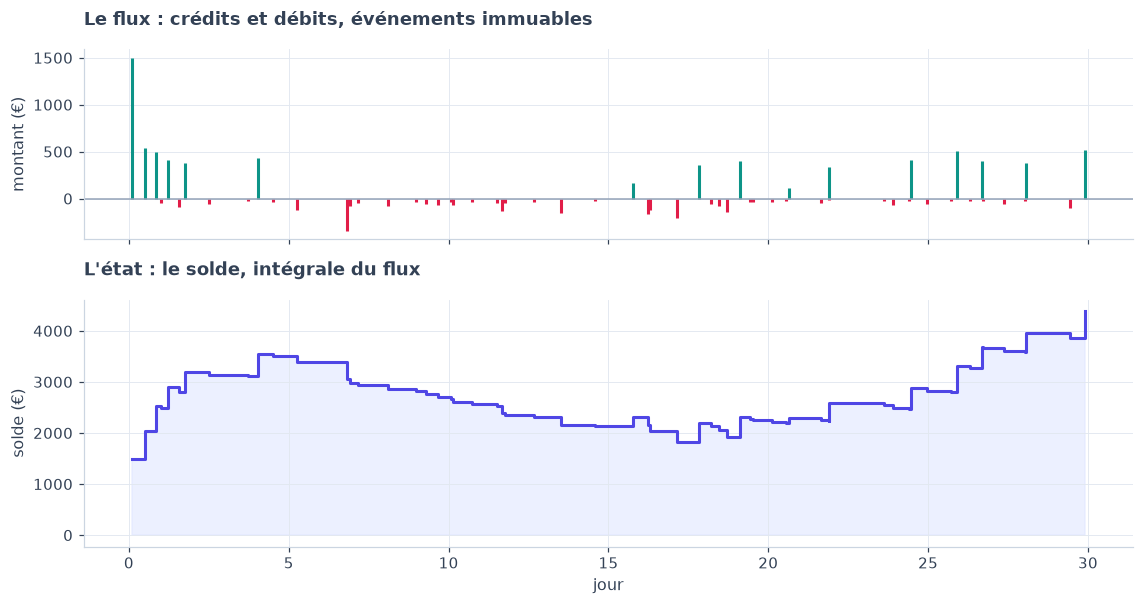

dériver le solde redonne exactement les événements : True


In [2]:
n = 60
t_ev = np.sort(rng.uniform(0, 30, n))
montants = np.where(rng.random(n) < 0.35, rng.normal(400, 120, n), -rng.gamma(2, 40, n)).round(0)
montants[0] = 1500
solde = np.cumsum(montants)                       # intégrer le flux donne l'état
retrouves = np.diff(np.concatenate([[0], solde]))  # dériver l'état redonne le flux
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10.5, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.3]))
ax.vlines(t_ev, 0, montants, color=np.where(montants > 0, TEAL, ROSE), lw=2)
ax.axhline(0, color=GRAY, lw=1)
ax.set_ylabel("montant (€)"); ax.set_title("Le flux : crédits et débits, événements immuables")
ax2.step(t_ev, solde, where="post", color=INDIGO)
ax2.fill_between(t_ev, solde, step="post", color=LIGHT[INDIGO], alpha=0.6)
ax2.set_ylabel("solde (€)"); ax2.set_xlabel("jour")
ax2.set_title("L'état : le solde, intégrale du flux")
plt.tight_layout(); plt.show()
print("dériver le solde redonne exactement les événements :", np.allclose(retrouves, montants))

Si l'on conserve durablement le journal des changements, l'état devient simplement
**reproductible**. En considérant le journal comme le système de référence et tout état
modifiable comme dérivé, il devient plus facile de raisonner sur les flux de données d'un
système. Jim Gray et Andreas Reuter le disaient dès 1992 : au fond, le journal contient
toute l'information, et la base de données (l'état « au bout du journal ») n'existe que
pour lire plus vite. La compaction du cours 3 fait le pont entre les deux : elle ne garde
que la dernière version de chaque enregistrement.

> **À retenir.** L'état est l'intégrale du flux d'événements, le flux la dérivée de l'état.
> Garder le journal rend l'état reproductible ; l'état n'est qu'un cache du journal.

## 2. L'event sourcing (section *Event Sourcing*)

L'**event sourcing**, idée issue de la communauté de la conception pilotée par le domaine
(domain-driven design), stocke **tous les changements de l'état de l'application sous
forme d'événements**. Comme la CDC, il produit un journal de changements ; la différence
est le **niveau d'abstraction** :

- en CDC, l'application modifie la base librement ; le journal est extrait à bas niveau
  (lignes modifiées), ce qui garantit l'ordre réel des écritures ;
- en event sourcing, la logique de l'application est **construite** sur des événements
  immuables écrits dans un journal en ajout seul ; les événements décrivent ce qui s'est
  passé **au niveau métier** (« la place 12 a été réservée par Alice »), pas des
  changements d'état de bas niveau, et l'on évite ou interdit de les modifier.

**Commandes et événements.** Il faut distinguer la **commande**, demande d'un utilisateur
qui peut encore échouer (réserver une place déjà prise), et l'**événement**, produit
seulement si la commande est validée : c'est alors un **fait**, durable et immuable. Même
si l'utilisateur annule plus tard, la réservation a bien eu lieu ; l'annulation est un
nouvel événement. La validation doit se faire de façon synchrone, avant l'écriture de
l'événement (par exemple dans une transaction sérialisable qui valide la commande et
ajoute l'événement atomiquement).

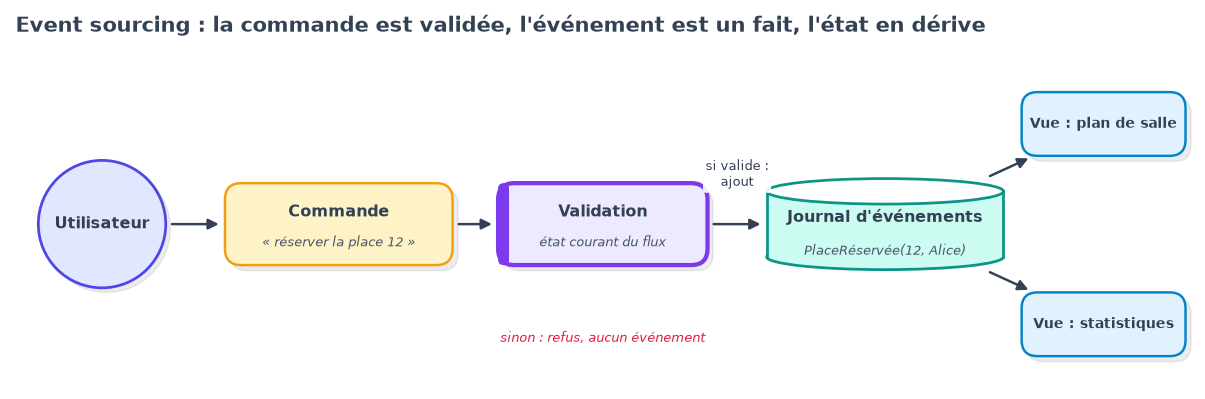

In [3]:
d = Diagram(13, 3.6, title="Event sourcing : la commande est validée, l'événement est un fait, l'état en dérive")
d.box("u", 1.0, 1.8, "Utilisateur", color=INDIGO, kind="user", w=1.4)
d.box("cmd", 3.6, 1.8, "Commande", sub="« réserver la place 12 »", color=AMBER, w=2.5)
d.box("val", 6.5, 1.8, "Validation", sub="état courant du flux", color=VIOLET, w=2.3, kind="model")
d.box("log", 9.6, 1.8, "Journal d'événements", sub="PlaceRéservée(12, Alice)", color=TEAL, kind="db", w=2.6, h=1.0)
d.box("vue", 12.0, 2.9, "Vue : plan de salle", color=SKY, w=1.8, h=0.7, fontsize=9)
d.box("vue2", 12.0, 0.7, "Vue : statistiques", color=SKY, w=1.8, h=0.7, fontsize=9)
d.arrow("u", "cmd")
d.arrow("cmd", "val")
d.arrow("val", "log", "si valide :\najout", label_offset=(0, 0.55))
d.arrow("log", "vue", "")
d.arrow("log", "vue2", "")
d.note(6.5, 0.55, "sinon : refus, aucun événement", color=ROSE, fontsize=8.5)
d.show()

Implémentons une petite salle de spectacle avec `st.EventStore`. Un agrégat (un spectacle)
a son flux d'événements ; une fonction `appliquer` plie les événements en état (le plan de
salle), une fonction `decider` transforme une commande en événements après validation.

In [4]:
def appliquer(etat, e):
    etat = dict(etat or {})
    if e.type == "PlaceReservee":
        etat[e.data["place"]] = e.data["client"]
    elif e.type == "ReservationAnnulee":
        etat.pop(e.data["place"], None)
    return etat

def decider(etat, commande):
    """Commande -> liste d'événements (vide si refusée)."""
    typ, place, client = commande
    etat = etat or {}
    if typ == "reserver":
        return [] if place in etat else [("PlaceReservee", {"place": place, "client": client})]
    if typ == "annuler":
        return [("ReservationAnnulee", {"place": place, "client": client})] if etat.get(place) == client else []
    raise ValueError(typ)

es = st.EventStore()
refus = 0
for cmd in [("reserver", 12, "Alice"), ("reserver", 13, "Bob"), ("reserver", 12, "Chloé"),
            ("annuler", 12, "Alice"), ("reserver", 12, "Chloé"), ("annuler", 13, "Alice")]:
    flux = es.read("spectacle-1")
    etat = st.replay(flux, appliquer)
    evts = decider(etat, cmd)
    if evts:
        es.append("spectacle-1", evts, expected_version=len(flux))
    else:
        refus += 1
print("état courant :", st.replay(es.read("spectacle-1"), appliquer), f"; commandes refusées : {refus}")
pd.DataFrame([{"version": e.version, "événement": e.type, **e.data} for e in es.read("spectacle-1")]).set_index("version")

état courant : {13: 'Bob', 12: 'Chloé'} ; commandes refusées : 2


,événement,place,client
version,,,
1,PlaceReservee,12,Alice
2,PlaceReservee,13,Bob
3,ReservationAnnulee,12,Alice
4,PlaceReservee,12,Chloé


Le journal garde toute l'histoire, y compris la réservation annulée d'Alice ; les deux
commandes invalides (place déjà prise, annulation par un tiers) n'ont laissé aucune trace.

**Rejeu et instantanés.** L'état courant se reconstruit en rejouant le journal, ce qui
devient coûteux quand il est long. Les applications en event sourcing stockent donc des
**instantanés** de l'état dérivé, pour ne rejouer que les événements postérieurs ; ce n'est
qu'une optimisation (de lecture et de reprise après panne) : l'intention reste de
pouvoir tout rejouer depuis l'origine. Mesurons le temps de chargement d'un agrégat de
$N$ événements, avec ou sans instantané tous les $k$ événements.

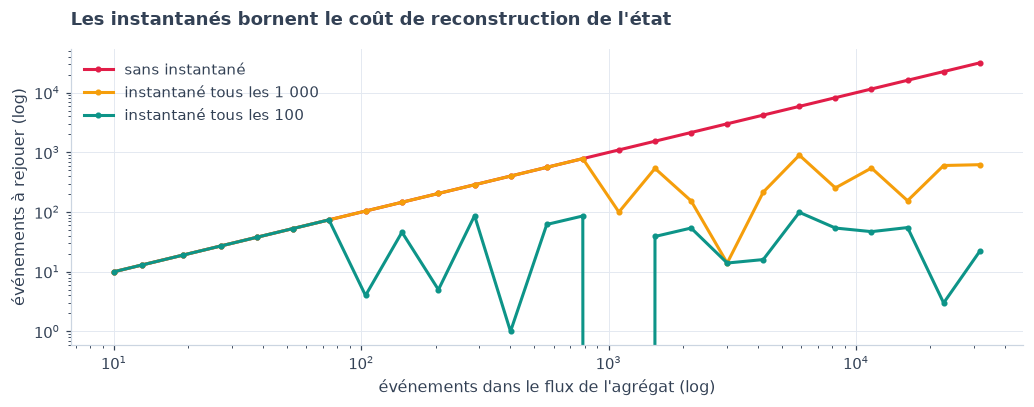

In [5]:
def charger(n_ev, k=None):
    """Nombre d'événements à rejouer et temps mesuré pour reconstruire l'état d'un agrégat."""
    evs = [st.Event("s", i + 1, "PlaceReservee" if i % 3 else "ReservationAnnulee",
                    {"place": i % 500, "client": "x"}) for i in range(n_ev)]
    if k:
        base = (n_ev // k) * k
        etat0 = st.replay(evs[:base], appliquer)            # instantané stocké, ici précalculé
        t0 = time.perf_counter(); st.replay(evs[base:], appliquer, dict(etat0 or {})); dt = time.perf_counter() - t0
        return n_ev - base, dt
    t0 = time.perf_counter(); st.replay(evs, appliquer); dt = time.perf_counter() - t0
    return n_ev, dt

Ns = np.unique(np.logspace(1, 4.5, 25).astype(int))
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for k, c, lab in [(None, ROSE, "sans instantané"), (1000, AMBER, "instantané tous les 1 000"), (100, TEAL, "instantané tous les 100")]:
    ax.plot(Ns, [charger(int(x), k)[0] for x in Ns], "o-", ms=3, color=c, label=lab)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("événements dans le flux de l'agrégat (log)"); ax.set_ylabel("événements à rejouer (log)")
ax.set_title("Les instantanés bornent le coût de reconstruction de l'état")
ax.legend()
plt.tight_layout(); plt.show()

Sans instantané, le coût croît linéairement avec l'historique ; avec un instantané tous
les $k$ événements, on rejoue au plus $k - 1$ événements, quel que soit l'âge de l'agrégat.

**Pas de compaction par clé.** C'est une différence importante avec la CDC. Un événement
de CDC contient la nouvelle version **complète** de la ligne : la dernière valeur d'une
clé suffit, on peut compacter. Un événement d'event sourcing exprime une **intention**
(« réserver », « annuler »), et les événements suivants ne remplacent pas les précédents :
il faut tout l'historique pour reconstruire l'état. Vérifions-le en compactant à tort le
flux par numéro de place.

In [6]:
flux = es.read("spectacle-1")
par_cle = {}
for e in flux:
    par_cle[e.data["place"]] = e                         # « dernière valeur par clé »
compacte = sorted(par_cle.values(), key=lambda e: e.version)
print("état complet :", st.replay(flux, appliquer))
print("état après compaction par clé :", st.replay(compacte, appliquer))
cdc = [("places", 12, "Alice"), ("places", 13, "Bob"), ("places", 12, None), ("places", 12, "Chloé")]
print("CDC compactée (valeurs complètes) :", {k: v for _, k, v in st.compact_records([(k, v) for _, k, v in cdc])})

état complet : {13: 'Bob', 12: 'Chloé'}
état après compaction par clé : {13: 'Bob', 12: 'Chloé'}
CDC compactée (valeurs complètes) : {13: 'Bob', 12: 'Chloé'}


Ici la compaction par clé donne, par chance, le bon état, car chaque place a été
réservée en dernier. Il suffit d'un événement relatif qui dépend des précédents pour que
ce ne soit plus le cas : par exemple « ajouter 2 articles au panier », puis « en retirer
1 ». Garder le dernier événement du panier (« retirer 1 ») perd l'information.

In [7]:
panier = [("Ajout", "stylo", 2), ("Ajout", "cahier", 1), ("Retrait", "stylo", 1), ("Ajout", "stylo", 3)]
def plier(evts):
    q = {}
    for typ, art, n in evts:
        q[art] = q.get(art, 0) + (n if typ == "Ajout" else -n)
    return q
dernier = {}
for ev in panier:
    dernier[ev[1]] = ev
print("état exact :", plier(panier), "| après compaction par article :", plier(dernier.values()))

état exact : {'stylo': 4, 'cahier': 1} | après compaction par article : {'stylo': 3, 'cahier': 1}


> **À retenir.** L'event sourcing stocke des faits métier immuables, produits par des
> commandes validées ; l'état se reconstruit par rejeu, accéléré par des instantanés. Ses
> événements exprimant des intentions, son journal ne se compacte pas par clé.

## 3. Les avantages des événements immuables (section *Advantages of immutable events*)

L'immutabilité est une vieille idée : les comptables l'appliquent depuis des siècles. Une
opération est inscrite dans un **grand livre** en ajout seul ; les comptes (résultat,
bilan) en sont dérivés par sommation. Une erreur ne s'efface pas : on ajoute une
**écriture de correction** (un remboursement), et l'erreur reste visible pour l'audit.
Si des chiffres faux ont déjà été publiés, la période suivante inclut la correction.

Au-delà de la finance, cela facilite la **reprise après un bogue**. Simulons un code
défectueux, déployé pendant une heure, qui applique deux fois la TVA. Avec une base
modifiable, les montants ont été écrasés : il faut deviner quelles lignes corriger. Avec
un journal d'événements bruts, on corrige la projection et on la **rejoue**.

In [8]:
ventes = [{"id": i, "ht": float(rng.integers(10, 200)), "heure": h}
          for i, h in enumerate(np.sort(rng.uniform(0, 5, 300)))]
def projection_ttc(evts, bug=False):
    """Total TTC par heure ; la version boguée applique deux fois la TVA entre 2 h et 3 h."""
    tot = {}
    for v in evts:
        taux = 1.2 * (1.2 if bug and 2 <= v["heure"] < 3 else 1.0)
        tot[int(v["heure"])] = tot.get(int(v["heure"]), 0) + v["ht"] * taux
    return tot
mutable = projection_ttc(ventes, bug=True)                  # état écrasé par le code bogué
rejoue = projection_ttc(ventes)                              # correction : on rejoue le journal brut
juste = {h: sum(v["ht"] * 1.2 for v in ventes if int(v["heure"]) == h) for h in range(5)}
pd.DataFrame({"base modifiable (après le bogue)": mutable, "journal rejoué (code corrigé)": rejoue,
              "valeur exacte": juste}).round(0).T

,0,1,2,3,4
base modifiable (après le bogue),7434.0,7214.0,10106.0,9424.0,7129.0
journal rejoué (code corrigé),7434.0,7214.0,8422.0,9424.0,7129.0
valeur exacte,7434.0,7214.0,8422.0,9424.0,7129.0


Le rejeu retrouve exactement les bons totaux, parce que les événements bruts n'ont jamais
été modifiés. Le journal sert aussi au **support client**, qui peut retracer ce qui est
arrivé à un utilisateur.

Les événements immuables **capturent plus d'information** que l'état courant. Sur un site
marchand, un client ajoute un article à son panier puis le retire : pour la livraison,
le second événement annule le premier, mais pour l'analyse, savoir que le client a hésité
sur cet article est précieux. Une base qui supprime la ligne du panier perd cette
information.

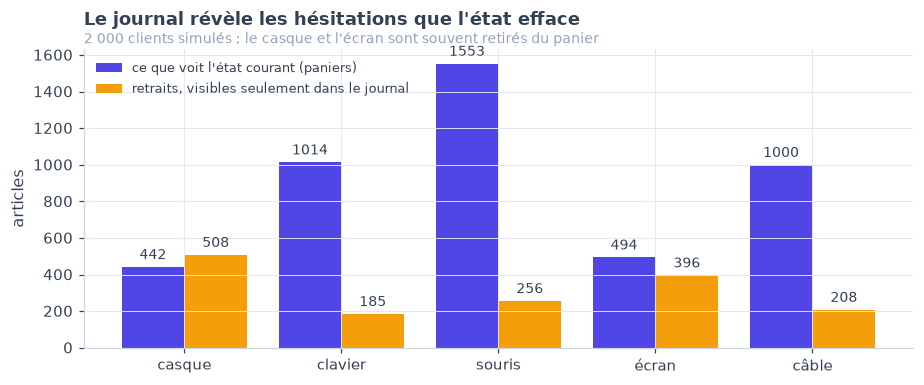

In [9]:
evs_paniers = []
articles = ["casque", "clavier", "souris", "écran", "câble"]
for client in range(2000):
    for _ in range(int(rng.integers(1, 6))):
        a = str(rng.choice(articles, p=[0.15, 0.2, 0.3, 0.15, 0.2]))
        evs_paniers.append((client, "Ajout", a))
        if rng.random() < {"casque": 0.55, "écran": 0.45}.get(a, 0.15):
            evs_paniers.append((client, "Retrait", a))
E = pd.DataFrame(evs_paniers, columns=["client", "type", "article"])
ajouts = E[E.type == "Ajout"].groupby("article").size()
retraits = E[E.type == "Retrait"].groupby("article").size()
etat_final = (ajouts - retraits)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(articles))
ax.bar(x - 0.2, etat_final[articles], 0.4, color=INDIGO, label="ce que voit l'état courant (paniers)")
ax.bar(x + 0.2, retraits[articles], 0.4, color=AMBER, label="retraits, visibles seulement dans le journal")
ax.set_xticks(x, articles); ax.set_ylabel("articles")
ax.set_title("Le journal révèle les hésitations que l'état efface")
subtitle(ax, "2 000 clients simulés ; le casque et l'écran sont souvent retirés du panier")
annotate_bars(ax, "{:.0f}")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Un journal immuable s'audite, se corrige par compensation et se rejoue
> après un bogue ; il conserve des informations (hésitations, annulations) que l'état
> courant efface.